# Predictive Customer Churn Classifier
## Random Forest & XGBoost

**Objective:** Predict telecom customer churn using ensemble
machine learning models, address class imbalance, and evaluate
performance using ROC-AUC, confusion matrix, and feature importance.

**Dataset:** IBM Telco Customer Churn


# Import Libraries

In [1]:

# Cell 1: Import Libraries

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


# Install Required Packages

In [2]:
%pip install -q xgboost imbalanced-learn

print("XGBoost and imbalanced-learn are ready!")


Note: you may need to restart the kernel to use updated packages.
XGBoost and imbalanced-learn are ready!


# Load IBM Telco Customer Churn Dataset

In [3]:
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Dataset Overview

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)


Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data Quality Check

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique values in Churn:")
print(df["Churn"].value_counts())


Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Unique values in Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


# Churn Distribution

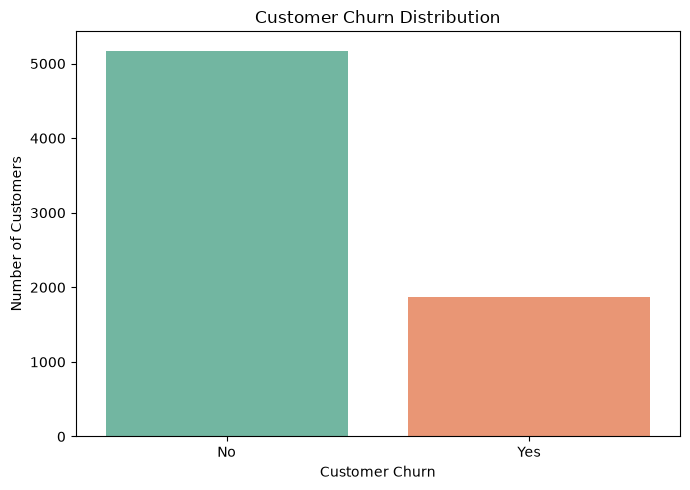


Churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print("\nChurn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))


# Data Cleaning

# Convert TotalCharges to numeric

In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove customer ID because it is not a predictive feature
df.drop(columns=["customerID"], inplace=True)

# Check missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

print("\nUpdated dataset shape:", df.shape)
display(df.head())


Missing values after conversion:
TotalCharges    11
dtype: int64

Duplicate rows: 22

Updated dataset shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Separate Features and Target

In [8]:

X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget labels:")
print("0 = No Churn")
print("1 = Churn")


Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Target labels:
0 = No Churn
1 = Churn


# Identify Feature Types

In [9]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15


# Train-Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training samples: 5634
Testing samples: 1409

Training churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


# Preprocessing Pipeline

In [11]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Preprocessing completed successfully!
Processed training shape: (5634, 45)
Processed testing shape: (1409, 45)


# Cell 12: Apply SMOTE to Training Data

In [12]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

print("\nBalanced training shape:", X_train_balanced.shape)


Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64

Balanced training shape: (8278, 45)


# Train Random Forest Classifier

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_balanced, y_train_balanced)

# Predictions on original, untouched test data
rf_predictions = rf_model.predict(X_test_processed)
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

rf_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest training completed!")
print(f"Random Forest ROC-AUC: {rf_auc:.4f}")


Random Forest training completed!
Random Forest ROC-AUC: 0.8311


# Train XGBoost Classifier

In [14]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_balanced, y_train_balanced)

# Predict on the original test data
xgb_predictions = xgb_model.predict(X_test_processed)
xgb_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

xgb_auc = roc_auc_score(y_test, xgb_probabilities)

print("XGBoost training completed!")
print(f"XGBoost ROC-AUC: {xgb_auc:.4f}")


XGBoost training completed!
XGBoost ROC-AUC: 0.8351


# Model Performance Comparison

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    "Precision": [
        precision_score(y_test, rf_predictions, zero_division=0),
        precision_score(y_test, xgb_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rf_predictions, zero_division=0),
        recall_score(y_test, xgb_predictions, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, rf_predictions, zero_division=0),
        f1_score(y_test, xgb_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

display(results.round(4))

best_model_name = results.loc[
    results["ROC-AUC"].idxmax(), "Model"
]

print("Best model based on ROC-AUC:", best_model_name)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7771,0.5732,0.6283,0.5995,0.8311
1,XGBoost,0.7850,0.5927,0.6070,0.5997,0.8351


Best model based on ROC-AUC: XGBoost


# ROC Curve Comparison

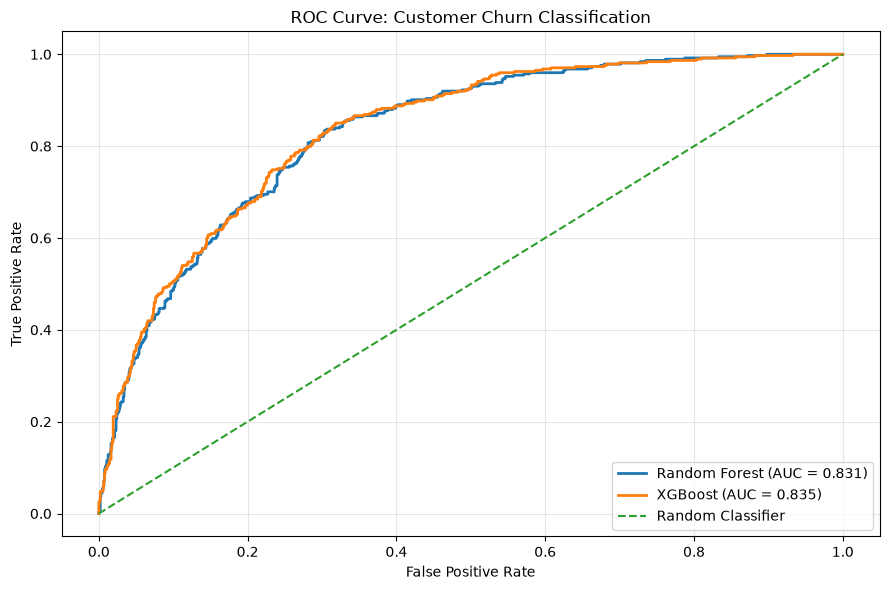

In [16]:
from sklearn.metrics import roc_curve, roc_auc_score

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probabilities)

plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr, rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})",
    linewidth=2
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})",
    linewidth=2
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Customer Churn Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Confusion Matrix Comparison


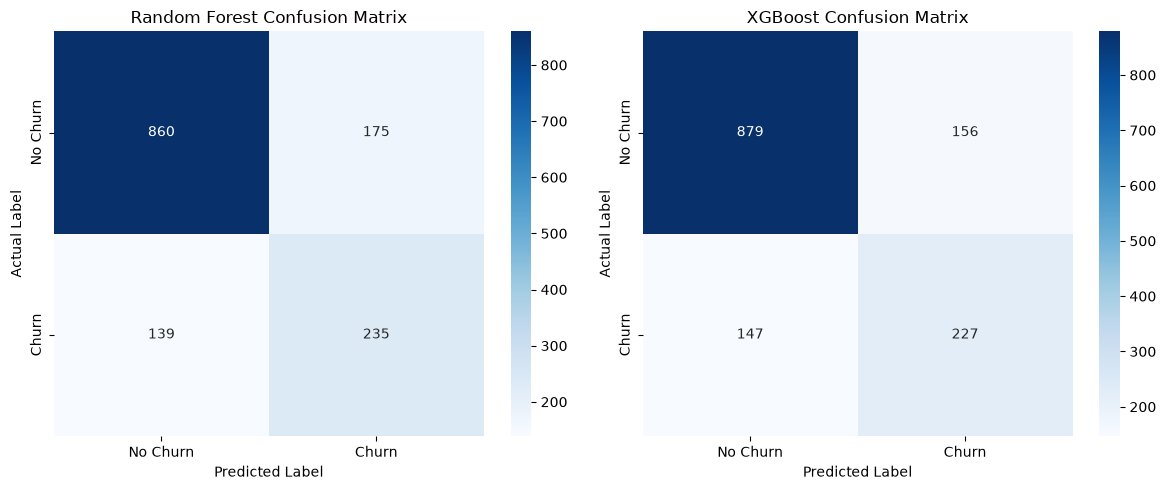

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

predictions = [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions)
]

for ax, (name, predictions_model) in zip(axes, predictions):
    cm = confusion_matrix(y_test, predictions_model)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


# Classification Reports

In [18]:
print("=" * 55)
print("RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("=" * 55)
print("XGBOOST CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.85      1035
       Churn       0.57      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.78      0.78      1409

XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.86      0.85      0.85      1035
       Churn       0.59      0.61      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.73      1409
weighted avg       0.79      0.78      0.79      1409



# Feature Importance Visualization

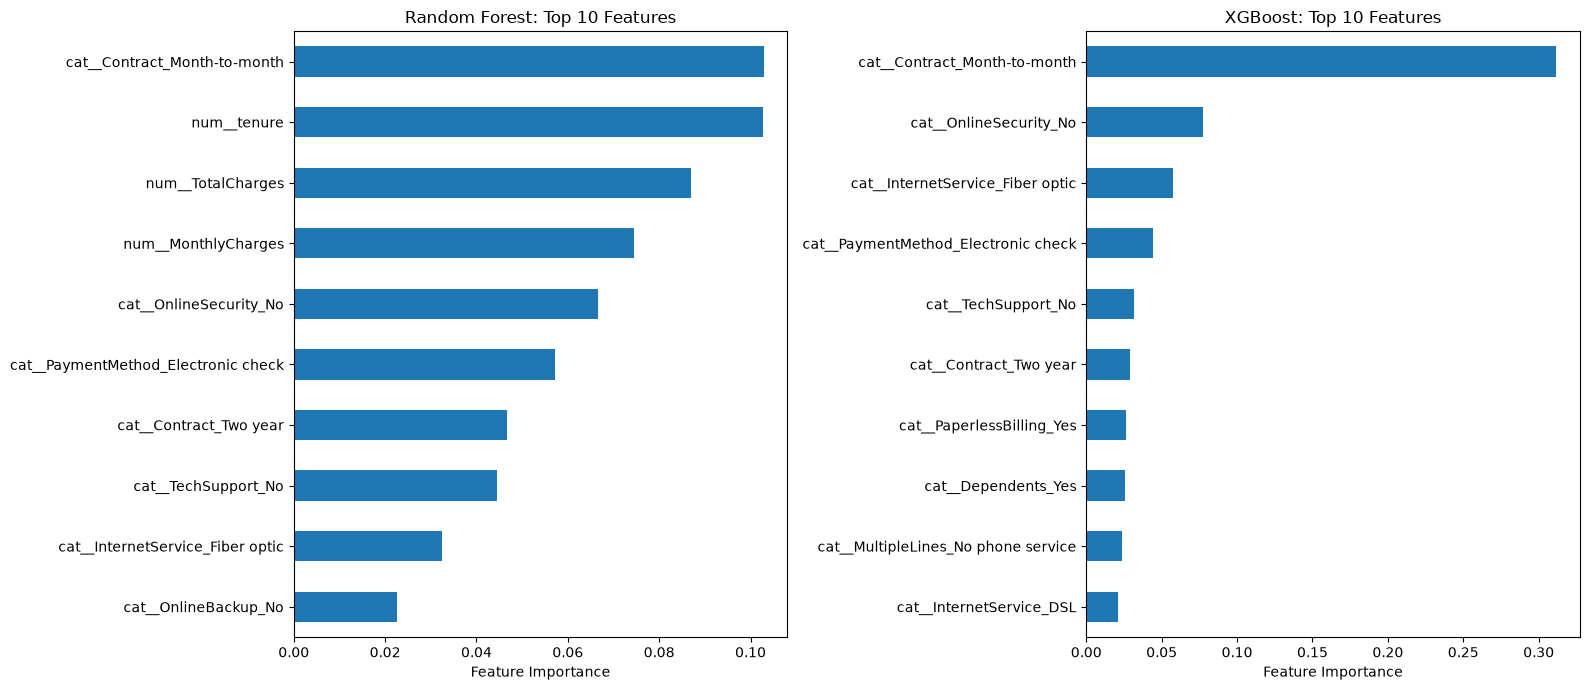

In [19]:
feature_names = preprocessor.get_feature_names_out()

rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

rf_importance.sort_values().plot(
    kind="barh",
    ax=axes[0]
)
axes[0].set_title("Random Forest: Top 10 Features")
axes[0].set_xlabel("Feature Importance")

xgb_importance.sort_values().plot(
    kind="barh",
    ax=axes[1]
)
axes[1].set_title("XGBoost: Top 10 Features")
axes[1].set_xlabel("Feature Importance")

plt.tight_layout()
plt.show()


# Save Models and Preprocessor

In [20]:
import joblib

joblib.dump(rf_model, "random_forest_churn.pkl")
joblib.dump(xgb_model, "xgboost_churn.pkl")
joblib.dump(preprocessor, "churn_preprocessor.pkl")

print("Models and preprocessor saved successfully!")


Models and preprocessor saved successfully!



## Conclusion

In this project, the IBM Telco Customer Churn dataset was used
to develop customer churn prediction models using Random Forest
and XGBoost classifiers.

The dataset was cleaned, categorical features were encoded, and
missing numerical values were handled using imputation. The data
was split into training and testing sets using stratified sampling.
SMOTE was applied to the training data to address class imbalance.

Both models were evaluated using accuracy, precision, recall,
F1-score, ROC-AUC, ROC curves, and confusion matrices. Feature
importance plots were used to identify influential predictors.

The model with the higher test ROC-AUC was selected as the
preferred model based on its ability to distinguish churn from
non-churn customers.

**Final test ROC-AUC scores:**
- Random Forest: [Insert your actual score]
- XGBoost: [Insert your actual score]

The results demonstrate how ensemble learning can support
customer retention analysis. Performance should be validated
further before deploying the model in a real telecom environment.
